# Reporte Curva de Calibración - EGOFETS

Visualización de transfers y cálculos estadísticos de curvas de calibración para la detección de proteínas.

Para cambiar de archivo, modifica la variable `hdf5_name` en la celda de setup.

In [9]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root(marker='src'):
    cwd = Path(os.getcwd()).resolve()
    for parent in [cwd, *cwd.parents]:
        if (parent / marker).is_dir():
            return parent
    raise FileNotFoundError(f"No se encontro project root con '{marker}'")

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

from src.readers.keithley_dean import list_measurements, read_curve, read_all_curves
from src.plotting import plot_transfer
from src.analysis import extract_vth_for_transfers

data_folder = PROJECT_ROOT / 'data' / 'raw'

print(f"Project root: {PROJECT_ROOT}")
print(f"Data folder:   {data_folder}")
print("Archivos disponibles:")
for f in sorted(os.listdir(data_folder)):
    print(f"  {f}")

# === Seleccionar archivo hdf5 (cambiar aqui) ===
hdf5_name = "2026-10-21_sensing-edit.hdf5"
hdf5_path = PROJECT_ROOT / 'data' / 'raw' / hdf5_name

print("-"*80)
print(f"Archivo: {hdf5_name}")
print(f"Ruta:    {hdf5_path}")

Project root: /home/dibarra/Documents/egofets-project
Data folder:   /home/dibarra/Documents/egofets-project/data/raw
Archivos disponibles:
  2026-06-26_test1.hdf5
  2026-06-29_test2.1.hdf5
  2026-06-29_test2.hdf5
  2026-06-30_test3.hdf5
  2026-07-01_test3.hdf5
  2026-07-08_biosensing_10_-6.hdf5
  2026-07-08_biosensing_10_-6_v2.hdf5
  2026-07-08_test.hdf5
  2026-07-16_testkapton.hdf5
  2026-07-22_kapton_and_old.hdf5
  2026-07-22_kapton_v2.hdf5
  2026-07-22_kapton_v3.hdf5
  2026-07-23 TMTES PS Phototransistor v3.hdf5
  2026-08-13_test2_kapton_v3.hdf5
  2026-09-04_kapton_test_out.hdf5
  2026-10-02_test.hdf5
  2026-10-21_SensingB2.hdf5
  2026-10-21_sensing-edit.hdf5
  2026-10-21_sensing.hdf5
  2026-10-22_sensingB3.hdf5
  2026-10-23_sensingB4_v2.hdf5
  notas.txt
--------------------------------------------------------------------------------
Archivo: 2026-10-21_sensing-edit.hdf5
Ruta:    /home/dibarra/Documents/egofets-project/data/raw/2026-10-21_sensing-edit.hdf5


In [10]:
measurement_list_dic = list_measurements(hdf5_path)
transfer_measurements = [m["name"] for m in measurement_list_dic if m["mode"] == "transfer"]
print(f"Transfer measurements ({len(transfer_measurements)}):")
for m in transfer_measurements:
    print(f"  - {m}")

Transfer measurements (21):
  - D1B2_E-12_00
  - D1B2_E-13_00
  - D1B2_E-14_00
  - D1B2_E-15_00
  - D1B2_E-16_00
  - D1B2_E-17_00
  - D1B2_Ref_00
  - D2B2_E-12_00
  - D2B2_E-13_00
  - D2B2_E-14_00
  - D2B2_E-15_00
  - D2B2_E-16_00
  - D2B2_E-17_00
  - D2B2_Ref_00
  - D3B2_E-12_00
  - D3B2_E-13_00
  - D3B2_E-14_00
  - D3B2_E-15_00
  - D3B2_E-16_00
  - D3B2_E-17_00
  - D3B2_Ref_00


## 3. Transfers agrupados por batch

Se detecta el batch a partir del nombre de cada medición (`D1B2_...` → `B2`) y se genera **una figura por batch**. En este archivo solo hay mediciones del batch `B2`.


Batches encontrados: B2
  B2: 21 mediciones


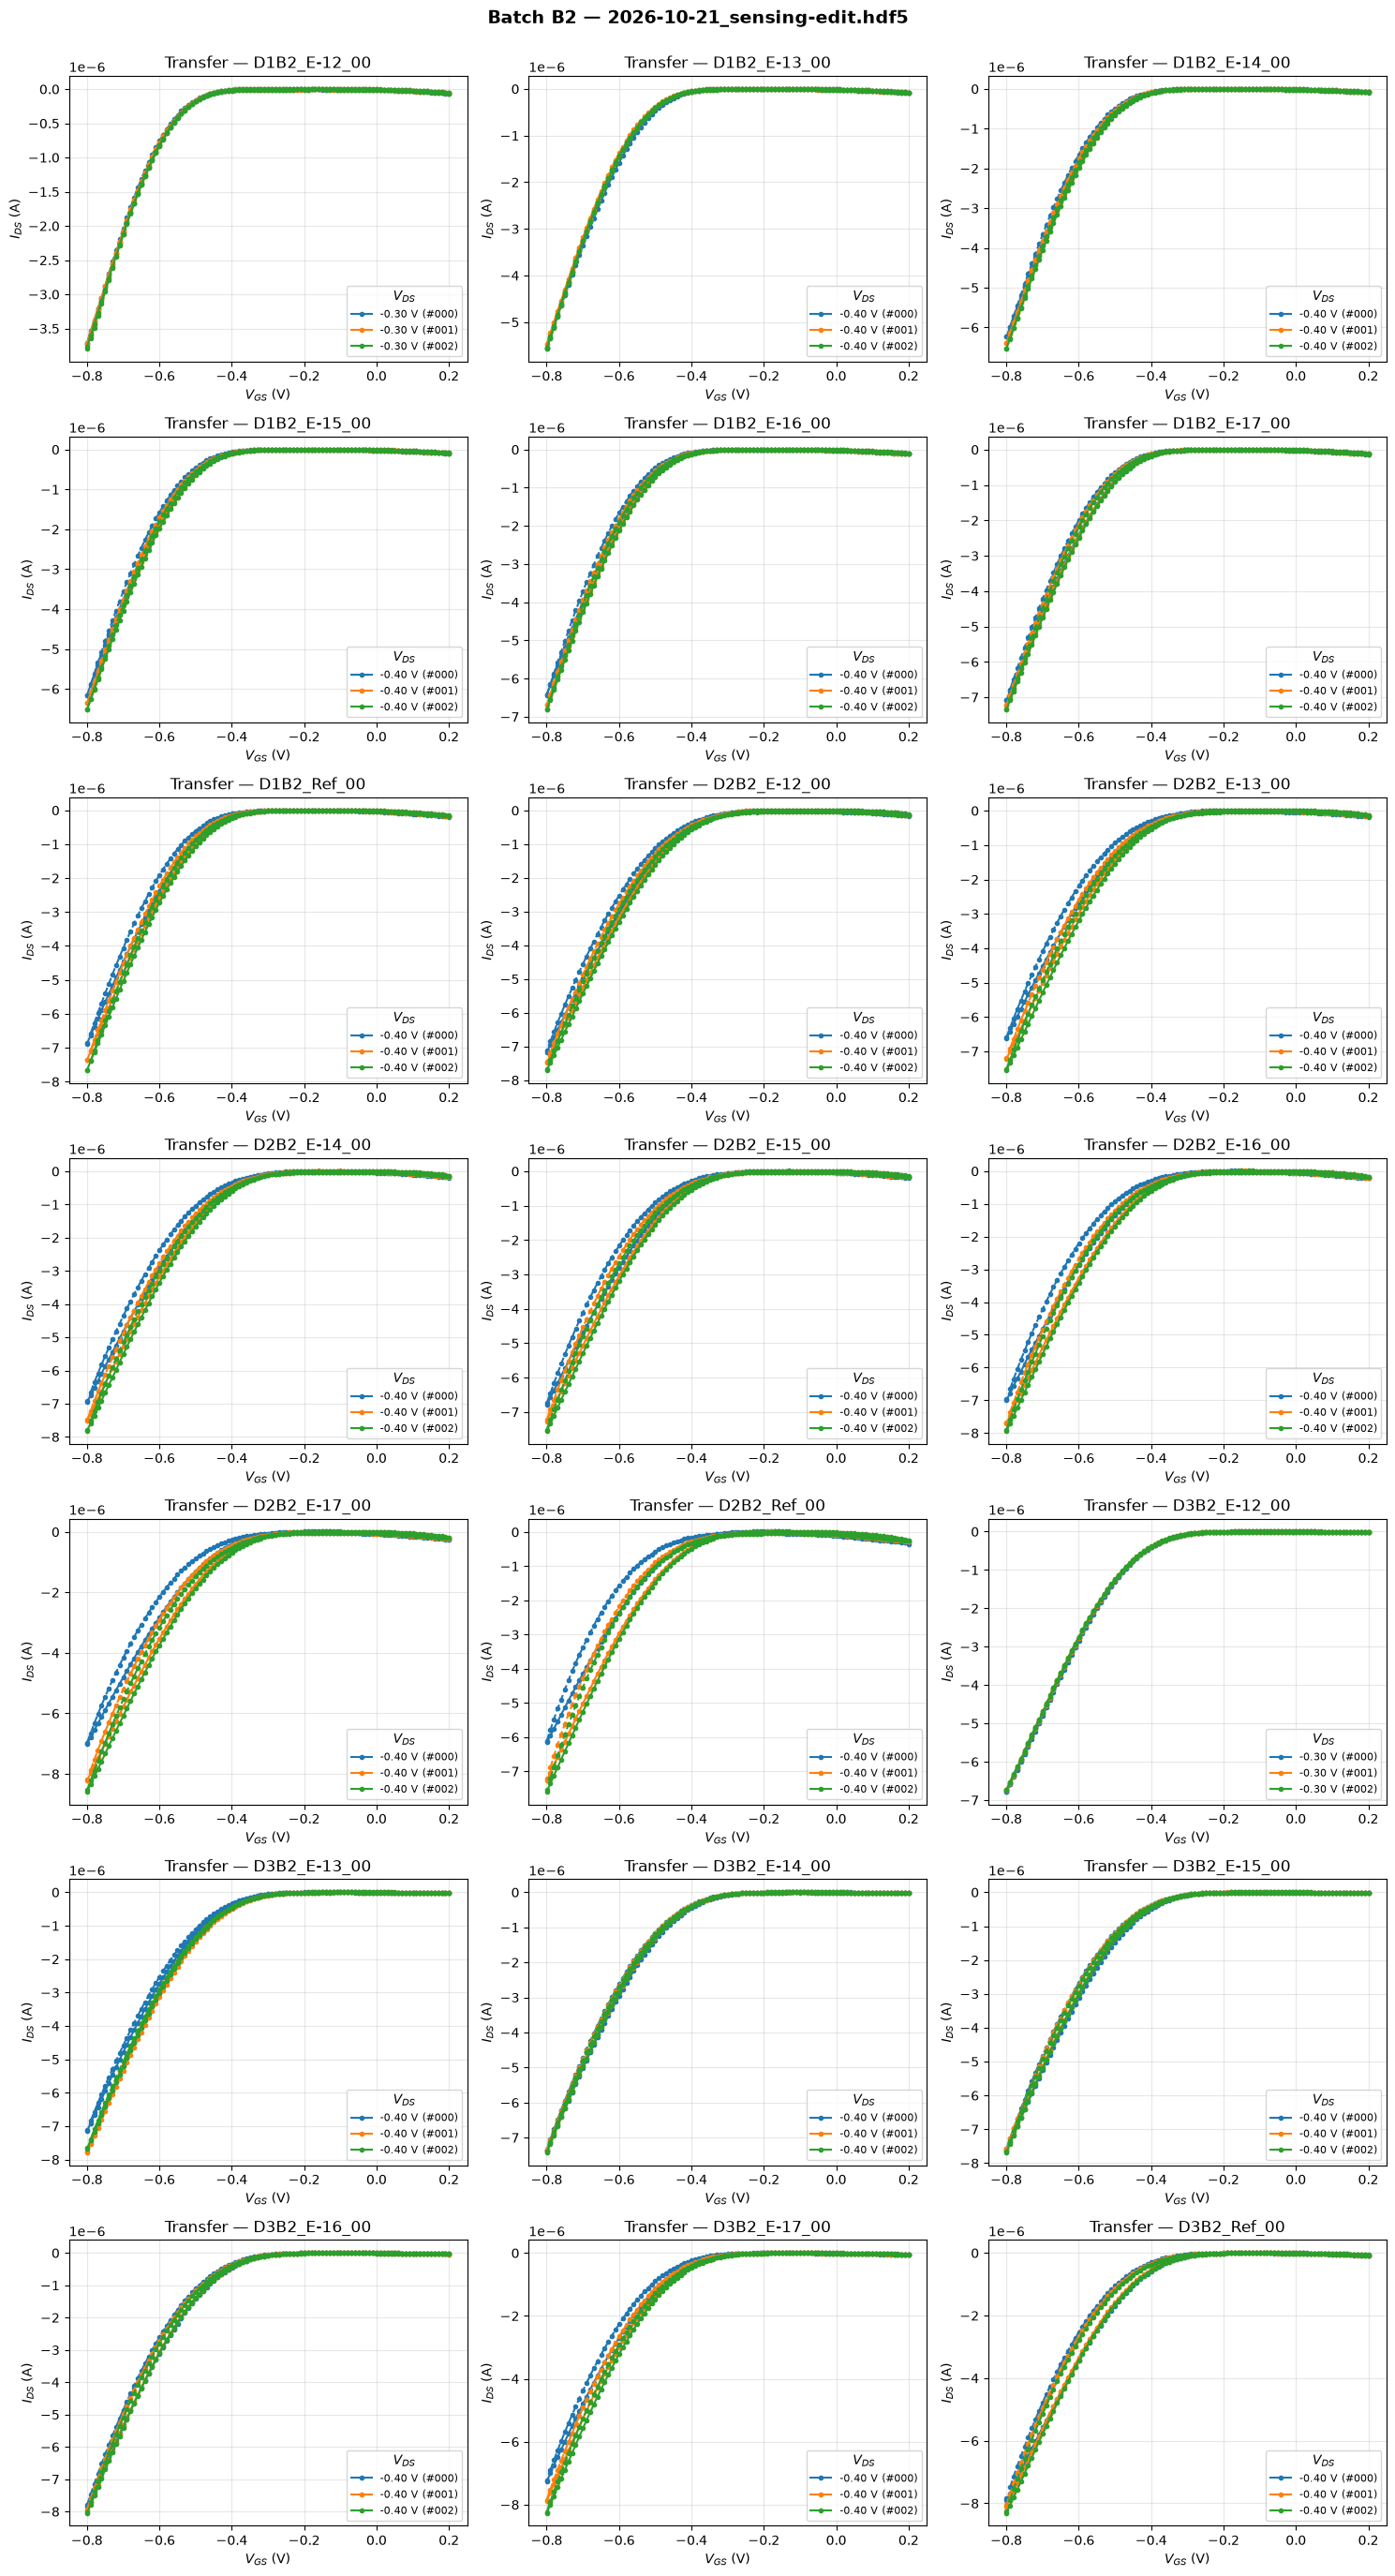

In [11]:
import re

def get_batch(measurement_name):
    """Extrae el batch del nombre, p. ej. 'D1B2_E-12_00' -> 'B2'."""
    match = re.match(r"^D\d+(B\d+)_", measurement_name)
    return match.group(1) if match else "Sin batch"

def plot_grid(hdf5_path, measurements, plot_func, ncols=3,
              figsize_per=(5, 4), title_suffix=None):
    n = len(measurements)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(figsize_per[0]*ncols, figsize_per[1]*nrows)
    )
    axes_flat = np.array(axes).flatten() if n > 1 else np.array([axes])
    for ax, m_name in zip(axes_flat, measurements):
        plot_func(hdf5_path, m_name, ax=ax)
    for ax in axes_flat[len(measurements):]:
        ax.set_visible(False)
    if title_suffix:
        fig.suptitle(title_suffix, fontsize=14, fontweight="bold")
        fig.tight_layout(rect=[0, 0, 1, 0.98])
    else:
        fig.tight_layout()
    return fig

# === Agrupar las mediciones por batch ===
batches = {}
for m_name in transfer_measurements:
    batches.setdefault(get_batch(m_name), []).append(m_name)

print(f"Batches encontrados: {', '.join(sorted(batches))}")
for batch, ms in sorted(batches.items()):
    print(f"  {batch}: {len(ms)} mediciones")

# === Una figura por batch ===
for batch, ms in sorted(batches.items()):
    fig = plot_grid(
        hdf5_path, ms, plot_transfer,
        title_suffix=f"Batch {batch} — {hdf5_name}",
    )
    plt.show()

## 4. Extracción de $V_{th}$ por repetición

Cada medición contiene **3 curvas** adquiridas en el mismo `V_DS` (repeticiones), no curvas a distintos `V_DS`. Para poder calcular la estadística descriptiva, se extrae $V_{th}$ de **cada curva** mediante un ajuste lineal de $\sqrt{|I_{DS}|}$ frente a $V_{GS}$.

> **Ventana de ajuste:** se usa una ventana fija de **-0.70 V a -0.40 V**. En estas curvas esa es la zona lineal de saturación. La ventana por defecto de `extract_vth_for_transfers` (-0.40 V a -0.05 V) cae en la zona de curvatura y da lugar a ventanas de pocos puntos; por eso aquí se usa una ventana fija más amplia.


In [12]:
from IPython.display import display
from scipy.stats import linregress
import re

# === Configuración del ajuste de Vth ===
VTH_WINDOW = (-0.70, -0.40)  # V; zona lineal de sqrt(|I_DS|) vs V_GS
MIN_POINTS = 5

def parse_measurement_name(name):
    """Devuelve (dispositivo, condición, log10_C, C_M) desde 'D1B2_E-12_00'."""
    match = re.match(r"^(D\d+)B\d+_(E-\d+|Ref)_", name)
    if match is None:
        raise ValueError(f"Nombre de medición no reconocido: {name}")
    device, condition = match.group(1), match.group(2)
    if condition == "Ref":
        return device, condition, np.nan, np.nan
    log10_c = float(condition.replace("E", ""))
    return device, condition, log10_c, 10.0 ** log10_c

def extract_vth_per_curve(hdf5_path, measurements, window=VTH_WINDOW):
    """Extrae Vth de todas las curvas (repeticiones) de cada medición."""
    rows = []
    for m_name in measurements:
        device, condition, log10_c, c_m = parse_measurement_name(m_name)
        for curve in read_all_curves(hdf5_path, m_name):
            v_gs, i_ds = read_curve(
                hdf5_path, m_name, curve["curve_name"], fwd_only=True
            )
            mask = (v_gs >= window[0]) & (v_gs <= window[1])
            if mask.sum() < MIN_POINTS:
                print(
                    f"{m_name}/{curve['curve_name']}: "
                    f"solo {mask.sum()} puntos en la ventana"
                )
                continue
            slope, intercept, r_value, _, _ = linregress(
                v_gs[mask], np.sqrt(np.abs(i_ds[mask]))
            )
            rows.append({
                "measurement": m_name,
                "device": device,
                "condition": condition,
                "log10_C": log10_c,
                "concentration_M": c_m,
                "curve": curve["curve_name"],
                "V_DS_V": float(curve["v_ds"][0]),
                "V_th_V": -intercept / slope,
                "R2": r_value ** 2,
                "n_points": int(mask.sum()),
            })
    return pd.DataFrame(rows)

df_vth = extract_vth_per_curve(hdf5_path, transfer_measurements)
print(f"Curvas procesadas: {len(df_vth)}")
display(df_vth.head(10))

Curvas procesadas: 63


,measurement,device,condition,log10_C,concentration_M,curve,V_DS_V,V_th_V,R2,n_points
0,D1B2_E-12_00,D1,E-12,-12.0,1.000000e-12,curve_000,-0.299993,-0.404210,0.992361,30
1,D1B2_E-12_00,D1,E-12,-12.0,1.000000e-12,curve_001,-0.300105,-0.404704,0.991243,30
2,D1B2_E-12_00,D1,E-12,-12.0,1.000000e-12,curve_002,-0.300047,-0.403838,0.991935,30
3,D1B2_E-13_00,D1,E-13,-13.0,1.000000e-13,curve_000,-0.400119,-0.370008,0.997809,30
4,D1B2_E-13_00,D1,E-13,-13.0,1.000000e-13,curve_001,-0.400136,-0.378645,0.996219,30
5,D1B2_E-13_00,D1,E-13,-13.0,1.000000e-13,curve_002,-0.400169,-0.377751,0.996313,30
6,D1B2_E-14_00,D1,E-14,-14.0,1.000000e-14,curve_000,-0.400093,-0.359516,0.998450,30
7,D1B2_E-14_00,D1,E-14,-14.0,1.000000e-14,curve_001,-0.400193,-0.358852,0.998428,30
8,D1B2_E-14_00,D1,E-14,-14.0,1.000000e-14,curve_002,-0.400014,-0.355330,0.998547,30
9,D1B2_E-15_00,D1,E-15,-15.0,1.000000e-15,curve_000,-0.400236,-0.363793,0.998158,30


## 5. Estadística descriptiva por concentración

Para cada dispositivo y condición se calculan:

- `n`: número de repeticiones.
- `Vth_mean_V`, `Vth_sd_V`: media y desviación estándar muestral ($n-1$).
- `Vth_sem_V`: error estándar de la media, $SD/\sqrt{n}$.
- `Vth_CV_pct`: coeficiente de variación, $100 \cdot SD / |\text{media}|$.
- `R2_mean`: calidad media del ajuste lineal usado para obtener $V_{th}$.

La condición `Ref` es la referencia (sin concentración).

In [13]:
# === Estadística descriptiva por dispositivo y condición ===
condition_order = ["Ref"] + [f"E-{i}" for i in range(12, 18)]
condition_meta = pd.DataFrame({
    "condition": condition_order,
    "log10_C": [np.nan] + list(range(-12, -18, -1)),
})
condition_meta["condition"] = pd.Categorical(
    condition_meta["condition"], categories=condition_order, ordered=True
)
condition_meta["concentration_M"] = 10.0 ** condition_meta["log10_C"]

df_vth["condition"] = pd.Categorical(
    df_vth["condition"], categories=condition_order, ordered=True
)

def descriptive_stats(df, group_cols):
    out = (
        df.groupby(group_cols, observed=True)["V_th_V"]
        .agg(n="count", mean="mean", sd=lambda s: s.std(ddof=1),
             vmin="min", vmax="max")
        .reset_index()
    )
    out["sem"] = out["sd"] / np.sqrt(out["n"])
    out["cv_pct"] = np.where(
        out["mean"].abs() > 0,
        out["sd"] / out["mean"].abs() * 100,
        np.nan,
    )
    return out

stats = descriptive_stats(df_vth, ["device", "condition"])
stats = stats.merge(
    df_vth.groupby(["device", "condition"], observed=True)["R2"]
    .mean().rename("R2_mean").reset_index(),
    on=["device", "condition"], how="left",
)
stats = stats.merge(
    condition_meta[["condition", "log10_C", "concentration_M"]],
    on="condition", how="left",
)
stats = stats.rename(columns={
    "mean": "Vth_mean_V", "sd": "Vth_sd_V", "sem": "Vth_sem_V",
    "vmin": "Vth_min_V", "vmax": "Vth_max_V", "cv_pct": "Vth_CV_pct",
})
stats = stats[[
    "device", "condition", "log10_C", "concentration_M", "n",
    "Vth_mean_V", "Vth_sd_V", "Vth_sem_V", "Vth_CV_pct",
    "Vth_min_V", "Vth_max_V", "R2_mean",
]]

def format_stats_table(df):
    out = df.copy()
    out["C_M"] = out["concentration_M"].map(
        lambda x: f"{x:.0e}" if pd.notna(x) else "—"
    )
    return out.drop(columns="concentration_M")

cols = [
    "device", "condition", "C_M", "log10_C", "n",
    "Vth_mean_V", "Vth_sd_V", "Vth_sem_V", "Vth_CV_pct",
    "Vth_min_V", "Vth_max_V", "R2_mean",
]
display(format_stats_table(stats)[cols].round(4))

,device,condition,C_M,log10_C,n,Vth_mean_V,Vth_sd_V,Vth_sem_V,Vth_CV_pct,Vth_min_V,Vth_max_V,R2_mean
0,D1,Ref,—,NaN,3,-0.3312,0.0054,0.0031,1.6287,-0.3368,-0.3260,0.9996
1,D1,E-12,1e-12,-12.0,3,-0.4043,0.0004,0.0003,0.1074,-0.4047,-0.4038,0.9918
2,D1,E-13,1e-13,-13.0,3,-0.3755,0.0047,0.0027,1.2649,-0.3786,-0.3700,0.9968
3,D1,E-14,1e-14,-14.0,3,-0.3579,0.0023,0.0013,0.6287,-0.3595,-0.3553,0.9985
4,D1,E-15,1e-15,-15.0,3,-0.3600,0.0037,0.0021,1.0278,-0.3638,-0.3564,0.9982
5,D1,E-16,1e-16,-16.0,3,-0.3554,0.0033,0.0019,0.9272,-0.3590,-0.3524,0.9986
6,D1,E-17,1e-17,-17.0,3,-0.3390,0.0009,0.0005,0.2734,-0.3398,-0.3380,0.9994
7,D2,Ref,—,NaN,3,-0.2844,0.0139,0.0080,4.8922,-0.3003,-0.2746,0.9998
8,D2,E-12,1e-12,-12.0,3,-0.2645,0.0028,0.0016,1.0689,-0.2662,-0.2613,0.9998
9,D2,E-13,1e-13,-13.0,3,-0.2728,0.0074,0.0043,2.7197,-0.2804,-0.2655,0.9999


In [14]:
# === Tabla resumen: media ± SD y CV por dispositivo ===
pivot_mean = stats.pivot(index="device", columns="condition", values="Vth_mean_V")
pivot_sd = stats.pivot(index="device", columns="condition", values="Vth_sd_V")
pivot_cv = stats.pivot(index="device", columns="condition", values="Vth_CV_pct")

summary = pivot_mean.map(lambda x: f"{x:.4f}") + " ± " + pivot_sd.map(lambda x: f"{x:.4f}")
print("Vth media ± SD (V)")
display(summary)

print("CV de Vth (%)")
display(pivot_cv.round(2))

# === Estadística global por condición (referencia) ===
# Nota: agrupa los 3 dispositivos; la SD incluye las diferencias de offset entre ellos.
global_stats = descriptive_stats(df_vth, ["condition"])
global_stats = global_stats.merge(
    df_vth.groupby("condition", observed=True)["R2"]
    .mean().rename("R2_mean").reset_index(),
    on="condition", how="left",
).merge(
    condition_meta[["condition", "log10_C", "concentration_M"]],
    on="condition", how="left",
)
global_stats = global_stats.rename(columns={
    "mean": "Vth_mean_V", "sd": "Vth_sd_V", "sem": "Vth_sem_V",
    "vmin": "Vth_min_V", "vmax": "Vth_max_V", "cv_pct": "Vth_CV_pct",
})[
    ["condition", "log10_C", "concentration_M", "n", "Vth_mean_V",
     "Vth_sd_V", "Vth_sem_V", "Vth_CV_pct", "Vth_min_V", "Vth_max_V",
     "R2_mean"]
]
gcols = [
    "condition", "C_M", "log10_C", "n", "Vth_mean_V", "Vth_sd_V",
    "Vth_sem_V", "Vth_CV_pct", "Vth_min_V", "Vth_max_V", "R2_mean",
]
print("Estadística global por condición (n = 9)")
display(format_stats_table(global_stats)[gcols].round(4))

Vth media ± SD (V)


condition,Ref,E-12,E-13,E-14,E-15,E-16,E-17
device,,,,,,,
D1,-0.3312 ± 0.0054,-0.4043 ± 0.0004,-0.3755 ± 0.0047,-0.3579 ± 0.0023,-0.3600 ± 0.0037,-0.3554 ± 0.0033,-0.3390 ± 0.0009
D2,-0.2844 ± 0.0139,-0.2645 ± 0.0028,-0.2728 ± 0.0074,-0.2637 ± 0.0057,-0.2686 ± 0.0044,-0.2657 ± 0.0092,-0.2652 ± 0.0158
D3,-0.2668 ± 0.0068,-0.2854 ± 0.0028,-0.2827 ± 0.0081,-0.2857 ± 0.0052,-0.2804 ± 0.0060,-0.2868 ± 0.0029,-0.2930 ± 0.0086


CV de Vth (%)


condition,Ref,E-12,E-13,E-14,E-15,E-16,E-17
device,,,,,,,
D1,1.63,0.11,1.26,0.63,1.03,0.93,0.27
D2,4.89,1.07,2.72,2.15,1.66,3.46,5.96
D3,2.53,0.99,2.86,1.80,2.12,1.00,2.94


Estadística global por condición (n = 9)


,condition,C_M,log10_C,n,Vth_mean_V,Vth_sd_V,Vth_sem_V,Vth_CV_pct,Vth_min_V,Vth_max_V,R2_mean
0,Ref,—,NaN,9,-0.2941,0.0300,0.0100,10.1915,-0.3368,-0.2591,0.9998
1,E-12,1e-12,-12.0,9,-0.3181,0.0653,0.0218,20.5284,-0.4047,-0.2613,0.9972
2,E-13,1e-13,-13.0,9,-0.3103,0.0494,0.0165,15.9206,-0.3786,-0.2655,0.9988
3,E-14,1e-14,-14.0,9,-0.3025,0.0428,0.0143,14.1636,-0.3595,-0.2578,0.9994
4,E-15,1e-15,-15.0,9,-0.3030,0.0433,0.0144,14.2735,-0.3638,-0.2643,0.9993
5,E-16,1e-16,-16.0,9,-0.3027,0.0410,0.0137,13.5305,-0.3590,-0.2580,0.9994
6,E-17,1e-17,-17.0,9,-0.2991,0.0335,0.0112,11.2103,-0.3398,-0.2527,0.9996


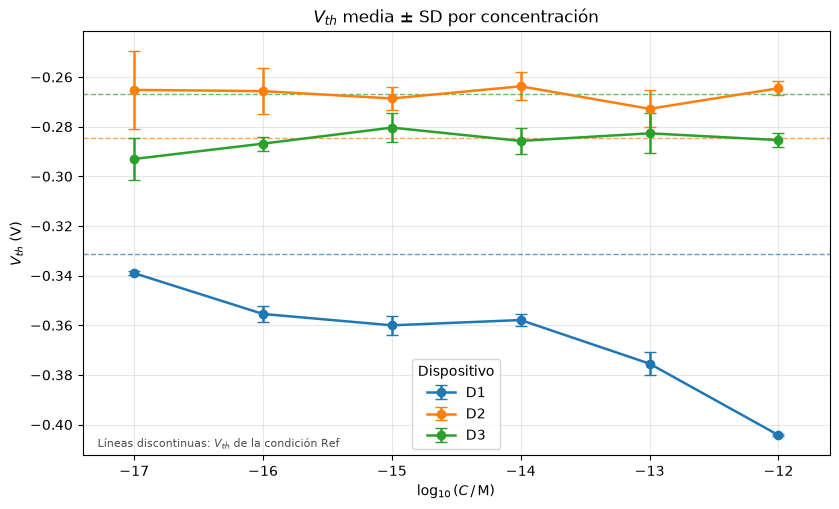

In [15]:
# === Figura descriptiva: Vth media ± SD frente a log10(C) ===
fig, ax = plt.subplots(figsize=(8.5, 5.2))
colors = {"D1": "C0", "D2": "C1", "D3": "C2"}

for device, sub in stats[stats["condition"] != "Ref"].groupby(
    "device", observed=True
):
    sub = sub.sort_values("log10_C")
    color = colors.get(device)
    ax.errorbar(
        sub["log10_C"], sub["Vth_mean_V"], yerr=sub["Vth_sd_V"],
        marker="o", ms=6, capsize=4, lw=1.8, color=color, label=device,
    )
    ref = stats[(stats["device"] == device) & (stats["condition"] == "Ref")]
    if not ref.empty:
        ax.axhline(
            ref["Vth_mean_V"].iloc[0], color=color, ls="--", lw=1, alpha=0.7
        )

ax.set_xlabel(r"$\log_{10}(C\,/\,\mathrm{M})$")
ax.set_ylabel(r"$V_{th}$ (V)")
ax.set_title(r"$V_{th}$ media $\pm$ SD por concentración")
ax.set_xticks(range(-17, -11))
ax.set_xlim(-17.4, -11.6)
ax.grid(True, alpha=0.3)
ax.legend(title="Dispositivo")
ax.text(
    0.02, 0.02, "Líneas discontinuas: $V_{th}$ de la condición Ref",
    transform=ax.transAxes, fontsize=8, color="0.3",
)
plt.tight_layout()
plt.show()

## 6. Exportación de resultados

Se guardan dos CSV en `output/`: uno con $V_{th}$ por curva y otro con la estadística descriptiva por dispositivo y condición.

In [16]:
# === Guardar resultados en output/ ===
out_dir = PROJECT_ROOT / "output"
out_dir.mkdir(parents=True, exist_ok=True)
stem = Path(hdf5_name).stem

per_curve_csv = out_dir / f"vth_per_curve_{stem}.csv"
stats_csv = out_dir / f"vth_descriptive_{stem}.csv"
#df_vth.to_csv(per_curve_csv, index=False)
#stats.to_csv(stats_csv, index=False)

#print(f"Guardado: {per_curve_csv}")
#print(f"Guardado: {stats_csv}")